In [1]:
# Telecom Customer Churn & Retention Analytics
# Python Exploratory Data Analysis (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the cleaned telecom churn dataset

data_path = "../data/telco_churn_cleaned.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Data Quality Check

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Customer IDs:", df["customerID"].nunique())

print("\nData Types:")
display(df.dtypes)

Dataset Shape: (7043, 21)

Missing Values:


TotalCharges    11
dtype: int64


Duplicate Rows: 0

Unique Customer IDs: 7043

Data Types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [4]:
# Churn Distribution Analysis

churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("Customer Churn Count:")
display(churn_counts)

print("\nCustomer Churn Percentage:")
display(churn_percentages.round(2))

print("\nTotal Customers:", len(df))
print("Churn Rate:", round((df["Churn"] == "Yes").mean() * 100, 2), "%")

Customer Churn Count:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Customer Churn Percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Total Customers: 7043
Churn Rate: 26.54 %


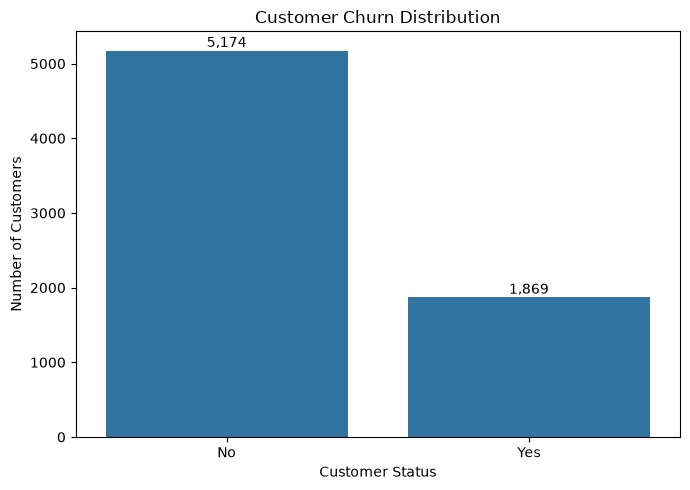

In [5]:
# Customer Churn Distribution

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for i, value in enumerate(churn_counts.values):
    plt.text(i, value + 50, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

In [6]:
# Tenure Group Analysis

bins = [0, 12, 24, 48, 72]
labels = ["0-12 months", "13-24 months", "25-48 months", "49-72 months"]

df["Tenure Group"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

tenure_churn = (
    df.groupby("Tenure Group", observed=False)
      .apply(lambda group: (group["Churn"] == "Yes").mean() * 100)
      .round(2)
)

print("Churn Rate by Customer Tenure:")
display(tenure_churn)

Churn Rate by Customer Tenure:


Tenure Group
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
dtype: float64

In [7]:
# Contract-wise Churn Analysis

contract_churn = (
    df.groupby("Contract")
      .agg(
          Total_Customers=("customerID", "count"),
          Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
      )
)

contract_churn["Churn_Rate_%"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Total_Customers"] * 100
).round(2)

display(contract_churn)

,Total_Customers,Churned_Customers,Churn_Rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


In [8]:
# Monthly Charges vs Churn

monthly_analysis = (
    df.groupby("Churn")["MonthlyCharges"]
      .agg(["count", "mean", "median"])
      .round(2)
)

monthly_analysis.index = monthly_analysis.index.map({
    "No": "Retained",
    "Yes": "Churned"
})

display(monthly_analysis)

,count,mean,median
Churn,,,
Retained,5174,61.27,64.43
Churned,1869,74.44,79.65


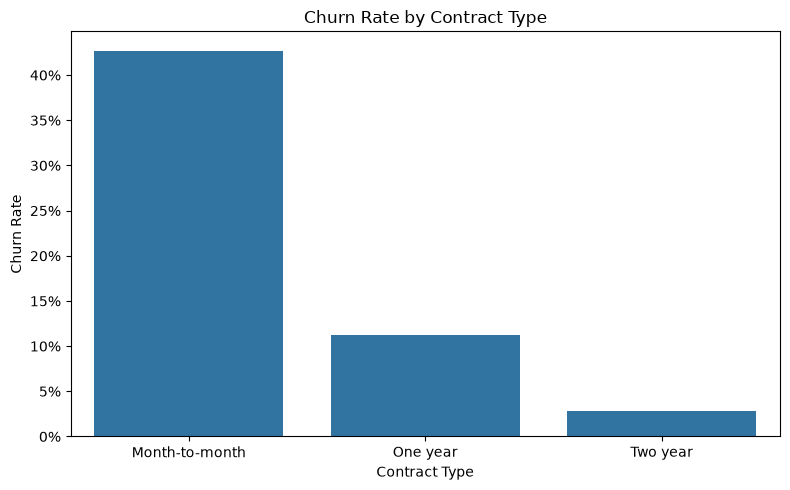

In [9]:
# Contract-wise Churn Rate Visualization

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Contract",
    y=df["Churn"].eq("Yes").astype(int),
    errorbar=None
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

## Business Insights & Recommendations

### Key Findings
1. **Overall Churn:** 1,869 out of 7,043 customers churned, resulting in a churn rate of 26.54%.
2. **Contract Type:** Month-to-month customers have the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
3. **Customer Tenure:** Customers with 0–12 months of tenure have the highest churn rate at 47.44%. Churn decreases as tenure increases.
4. **Monthly Charges:** Churned customers pay an average of 74.44 per month, compared with 61.27 for retained customers.

### Recommendations
- Introduce early-retention campaigns for customers during their first year.
- Offer suitable incentives to month-to-month customers to consider longer-term contracts.
- Investigate service quality, billing concerns, and support experiences among higher-paying customers.
- Track churn rate and retention rate regularly to evaluate the effectiveness of retention initiatives.

### Conclusion
The analysis identifies contract type, customer tenure, and monthly charges as useful indicators for understanding customer churn. These relationships are observational and do not establish causation. Targeted retention initiatives should be tested and evaluated using customer outcomes.
